In [1]:
from scipy import stats
import numpy as np
sample=[18000,25000,22000,15000,60000,75000,33000,30000]

sm=np.mean(sample)
sm

34750.0

In [2]:
# use sample mean to find the confidence interval

CI= stats.t.interval(confidence = 0.95, #used stats.t.interval because our list has less than 30 values. If the list has 30 or more values, we replace it with stats.z.interval as we will need to use z-distribution instead of t-distribution
                   df = len(sample)-1,# df is the variable used to store the length of the list - 1
                   loc=sm,# telling to use the mean as the central value
                   scale= stats.sem(sample))# the sem() function applies the confidence interval formula with the values stored in the list
print(CI)

(16843.03069921648, 52656.969300783516)


In [3]:
#linear regression algorithm 


In [4]:
import pandas as pd
df= pd.read_csv(r"C:\\COURSES\\DATA SCIENCE\\actual lessons\\Salary_Data.csv")
df

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
...,...,...,...,...,...,...
6699,49.0,Female,PhD,Director of Marketing,20.0,200000.0
6700,32.0,Male,High School,Sales Associate,3.0,50000.0
6701,30.0,Female,Bachelor's Degree,Financial Manager,4.0,55000.0
6702,46.0,Male,Master's Degree,Marketing Manager,14.0,140000.0


In [5]:
df.info

<bound method DataFrame.info of        Age  Gender    Education Level              Job Title  \
0     32.0    Male         Bachelor's      Software Engineer   
1     28.0  Female           Master's           Data Analyst   
2     45.0    Male                PhD         Senior Manager   
3     36.0  Female         Bachelor's        Sales Associate   
4     52.0    Male           Master's               Director   
...    ...     ...                ...                    ...   
6699  49.0  Female                PhD  Director of Marketing   
6700  32.0    Male        High School        Sales Associate   
6701  30.0  Female  Bachelor's Degree      Financial Manager   
6702  46.0    Male    Master's Degree      Marketing Manager   
6703  26.0  Female        High School        Sales Executive   

      Years of Experience    Salary  
0                     5.0   90000.0  
1                     3.0   65000.0  
2                    15.0  150000.0  
3                     7.0   60000.0  
4        

In [6]:
#EDA PROCESSES
df.columns

Index(['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience',
       'Salary'],
      dtype='object')

In [7]:
df.isnull().sum()

Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64

In [8]:
df=df.drop(["Education Level"],axis=1)# if axis=0, then will remove a row, if axis=1, then will remove the column
df #prints the df without the Education Level

,Age,Gender,Job Title,Years of Experience,Salary
0,32.0,Male,Software Engineer,5.0,90000.0
1,28.0,Female,Data Analyst,3.0,65000.0
2,45.0,Male,Senior Manager,15.0,150000.0
3,36.0,Female,Sales Associate,7.0,60000.0
4,52.0,Male,Director,20.0,200000.0
...,...,...,...,...,...
6699,49.0,Female,Director of Marketing,20.0,200000.0
6700,32.0,Male,Sales Associate,3.0,50000.0
6701,30.0,Female,Financial Manager,4.0,55000.0
6702,46.0,Male,Marketing Manager,14.0,140000.0


In [9]:
df.columns

Index(['Age', 'Gender', 'Job Title', 'Years of Experience', 'Salary'], dtype='object')

In [10]:
df["Gender"].value_counts()

Gender
Male      3674
Female    3014
Other       14
Name: count, dtype: int64

In [11]:
e=pd.get_dummies(df["Gender"]) # get_dummies converts the column values to a boolean value asmachines can't process objects
e

,Female,Male,Other
0,False,True,False
1,True,False,False
2,False,True,False
3,True,False,False
4,False,True,False
...,...,...,...
6699,True,False,False
6700,False,True,False
6701,True,False,False
6702,False,True,False


In [12]:
df= pd.concat([df,e],axis = 1) # axis is used to define whether its a row or column that needs to be removed. 1= column. 0=row
df

,Age,Gender,Job Title,Years of Experience,Salary,Female,Male,Other
0,32.0,Male,Software Engineer,5.0,90000.0,False,True,False
1,28.0,Female,Data Analyst,3.0,65000.0,True,False,False
2,45.0,Male,Senior Manager,15.0,150000.0,False,True,False
3,36.0,Female,Sales Associate,7.0,60000.0,True,False,False
4,52.0,Male,Director,20.0,200000.0,False,True,False
...,...,...,...,...,...,...,...,...
6699,49.0,Female,Director of Marketing,20.0,200000.0,True,False,False
6700,32.0,Male,Sales Associate,3.0,50000.0,False,True,False
6701,30.0,Female,Financial Manager,4.0,55000.0,True,False,False
6702,46.0,Male,Marketing Manager,14.0,140000.0,False,True,False


In [13]:
df.info

<bound method DataFrame.info of        Age  Gender              Job Title  Years of Experience    Salary  \
0     32.0    Male      Software Engineer                  5.0   90000.0   
1     28.0  Female           Data Analyst                  3.0   65000.0   
2     45.0    Male         Senior Manager                 15.0  150000.0   
3     36.0  Female        Sales Associate                  7.0   60000.0   
4     52.0    Male               Director                 20.0  200000.0   
...    ...     ...                    ...                  ...       ...   
6699  49.0  Female  Director of Marketing                 20.0  200000.0   
6700  32.0    Male        Sales Associate                  3.0   50000.0   
6701  30.0  Female      Financial Manager                  4.0   55000.0   
6702  46.0    Male      Marketing Manager                 14.0  140000.0   
6703  26.0  Female        Sales Executive                  1.0   35000.0   

      Female   Male  Other  
0      False   True  False

In [14]:
df=df.drop(["Gender"], axis=1) # we dont need the gender colum anymore as it won't work as it is an object
df

,Age,Job Title,Years of Experience,Salary,Female,Male,Other
0,32.0,Software Engineer,5.0,90000.0,False,True,False
1,28.0,Data Analyst,3.0,65000.0,True,False,False
2,45.0,Senior Manager,15.0,150000.0,False,True,False
3,36.0,Sales Associate,7.0,60000.0,True,False,False
4,52.0,Director,20.0,200000.0,False,True,False
...,...,...,...,...,...,...,...
6699,49.0,Director of Marketing,20.0,200000.0,True,False,False
6700,32.0,Sales Associate,3.0,50000.0,False,True,False
6701,30.0,Financial Manager,4.0,55000.0,True,False,False
6702,46.0,Marketing Manager,14.0,140000.0,False,True,False


In [15]:
df["Years of Experience"] = df["Years of Experience"].fillna(df["Years of Experience"].mean())
df["Years of Experience"] 

0        5.0
1        3.0
2       15.0
3        7.0
4       20.0
        ... 
6699    20.0
6700     3.0
6701     4.0
6702    14.0
6703     1.0
Name: Years of Experience, Length: 6704, dtype: float64

In [16]:
df.info

<bound method DataFrame.info of        Age              Job Title  Years of Experience    Salary  Female  \
0     32.0      Software Engineer                  5.0   90000.0   False   
1     28.0           Data Analyst                  3.0   65000.0    True   
2     45.0         Senior Manager                 15.0  150000.0   False   
3     36.0        Sales Associate                  7.0   60000.0    True   
4     52.0               Director                 20.0  200000.0   False   
...    ...                    ...                  ...       ...     ...   
6699  49.0  Director of Marketing                 20.0  200000.0    True   
6700  32.0        Sales Associate                  3.0   50000.0   False   
6701  30.0      Financial Manager                  4.0   55000.0    True   
6702  46.0      Marketing Manager                 14.0  140000.0   False   
6703  26.0        Sales Executive                  1.0   35000.0    True   

       Male  Other  
0      True  False  
1     False  

In [17]:
df["Years of Experience"].isnull().any()

False

In [18]:
df["Salary"] = df["Salary"].fillna(df["Salary"].mean())
df["Salary"] 

0        90000.0
1        65000.0
2       150000.0
3        60000.0
4       200000.0
          ...   
6699    200000.0
6700     50000.0
6701     55000.0
6702    140000.0
6703     35000.0
Name: Salary, Length: 6704, dtype: float64

In [19]:
df["Salary"].isnull().any()

False

In [20]:
#feature selection
#instal scikit-learn module

In [21]:
#pip install scikit-learn

In [22]:
from sklearn.model_selection import train_test_split #gives us the function to split data
x=df[["Years of Experience"]]#will accept as 1d arroy, but will sometimes reject. to be safe, use 2d array 
# x is input data
y=df["Salary"]#y is output data in 
x_test,x_train,y_test,y_train = train_test_split(x,y, train_size=0.8,random_state=42) #x_test,x_train,y_test,y_train splits the data of x and y. into
                                                                    #some of x will be stores in x_train, then the rest will be stored on x_test
                                                                    # we can choose how much we spit the values of x and y using train_size=,
                                                                    #random_state is used to stop jumbling up the data every time the code is excecuted so our training data is consistant

In [23]:
from sklearn.linear_model import LinearRegression # import the linear regression to find the relation between 2 variables
lr= LinearRegression() #create an object for the "LinearRegression class". a machine can't automatically pass a class, so we convert it to an object
lr.fit(x_train,y_train)# fit is used to load only the training data for x and y. 
                     # however, it literally is the x values we have given for training (x_train)

LinearRegression()

In [24]:
y_prediction=lr.predict(x_test) # predict() function is used to predict the y values (output) based on the x values (input)
y_prediction


array([260624.92358984,  92943.05266786, 127876.77577661, ...,
        78969.56342437,  85956.30804612,  64996.07418087])

In [25]:
lr.coef_ #this is our gradient/slope found via a function

array([6986.74462175])

In [26]:
lr.intercept_#runction for y intercept

58009.329559120706

In [27]:
from sklearn.metrics import r2_score # r2 is used to find accuracy
r2_score(y_test,y_prediction) # relates how close our training data is in comparison to our testing data

0.6541917639584245

In [28]:
import numpy as np

a=np.array([4]).reshape(-1,1) 
#when you have 4 years of experience
#reshape is to turn the column into a row and the row into a coumn
b=lr.predict(a)
# the years of experience is stored in a. b uses this to predict how much they
b

C:\Users\japeu\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([85956.30804612])

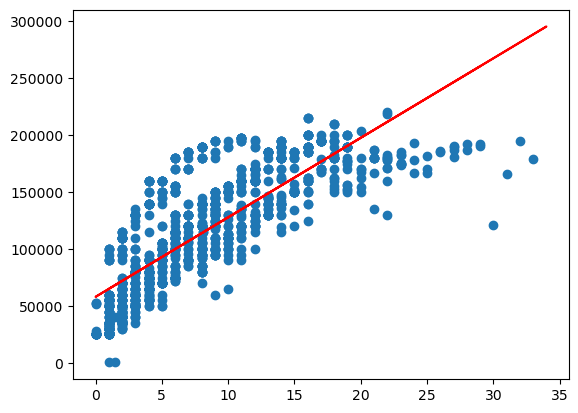

In [60]:
import matplotlib.pyplot as plt

plt.scatter(x_train,y_train)
plt.plot(x_test,y_prediction,color="red")
plt.show()